In [3]:
import numpy as np
import pandas as pd
import os

In [ ]:
# os.chdir("../")

In [5]:
df_train = pd.read_csv("artifacts/data_ingestion/train/_classes.csv")
df_test = pd.read_csv("artifacts/data_ingestion/test/_classes.csv")
df_valid = pd.read_csv("artifacts/data_ingestion/valid/_classes.csv")

In [6]:
df_train.head()

,filename,adenocarcinoma,adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib,large.cell.carcinoma,large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa,normal,squamous.cell.carcinoma,squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa
0,20-Copy-Copy_png.rf.f8106d9bc2c57cedf4f117eb02...,0,0,0,0,1,0,0
1,l3_png.rf.48a88c6a8e1ad36285285fd3846d4c7a.jpg,0,0,0,1,0,0,0
2,000055-3-_png.rf.a649a60f090a70246ce7393ebb43d...,0,0,0,1,0,0,0
3,000028-4-_png.rf.615fafe8701bb0541cad1468b7e82...,0,0,0,0,0,0,1
4,000025-6-_png.rf.a4baf2f1ed9039b04350584965199...,0,1,0,0,0,0,0


In [10]:
df_train['type'] = df_train.iloc[:,1:].idxmax(axis=1)

In [13]:
df_valid['type'] = df_valid.iloc[:,1:].idxmax(axis=1)
df_test['type'] = df_test.iloc[:,1:].idxmax(axis=1)

In [11]:
df_train.head()

,filename,adenocarcinoma,adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib,large.cell.carcinoma,large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa,normal,squamous.cell.carcinoma,squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa,type
0,20-Copy-Copy_png.rf.f8106d9bc2c57cedf4f117eb02...,0,0,0,0,1,0,0,normal
1,l3_png.rf.48a88c6a8e1ad36285285fd3846d4c7a.jpg,0,0,0,1,0,0,0,large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa
2,000055-3-_png.rf.a649a60f090a70246ce7393ebb43d...,0,0,0,1,0,0,0,large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa
3,000028-4-_png.rf.615fafe8701bb0541cad1468b7e82...,0,0,0,0,0,0,1,squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa
4,000025-6-_png.rf.a4baf2f1ed9039b04350584965199...,0,1,0,0,0,0,0,adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib


In [12]:
df_train['type'] = df_train['type'].replace({
    # Adenocarcinoma group
    "adenocarcinoma": "adenocarcinoma",
    "adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib": "adenocarcinoma",
    
    # Squamous cell group
    "squamous.cell.carcinoma": "squamous_cell",
    "squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa": "squamous_cell",

    # large cell group
    "large.cell.carcinoma": "large_cell",
    "large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa": "large_cell"
})


In [14]:
df_test['type'] = df_test['type'].replace({
    # Adenocarcinoma group
    "adenocarcinoma": "adenocarcinoma",
    "adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib": "adenocarcinoma",
    
    # Squamous cell group
    "squamous.cell.carcinoma": "squamous_cell",
    "squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa": "squamous_cell",

    # large cell group
    "large.cell.carcinoma": "large_cell",
    "large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa": "large_cell"
})

df_valid['type'] = df_valid['type'].replace({
    # Adenocarcinoma group
    "adenocarcinoma": "adenocarcinoma",
    "adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib": "adenocarcinoma",
    
    # Squamous cell group
    "squamous.cell.carcinoma": "squamous_cell",
    "squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa": "squamous_cell",

    # large cell group
    "large.cell.carcinoma": "large_cell",
    "large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa": "large_cell"
})


In [15]:
df_train.head()

,filename,adenocarcinoma,adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib,large.cell.carcinoma,large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa,normal,squamous.cell.carcinoma,squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa,type
0,20-Copy-Copy_png.rf.f8106d9bc2c57cedf4f117eb02...,0,0,0,0,1,0,0,normal
1,l3_png.rf.48a88c6a8e1ad36285285fd3846d4c7a.jpg,0,0,0,1,0,0,0,large_cell
2,000055-3-_png.rf.a649a60f090a70246ce7393ebb43d...,0,0,0,1,0,0,0,large_cell
3,000028-4-_png.rf.615fafe8701bb0541cad1468b7e82...,0,0,0,0,0,0,1,squamous_cell
4,000025-6-_png.rf.a4baf2f1ed9039b04350584965199...,0,1,0,0,0,0,0,adenocarcinoma


In [51]:
import shutil
from pathlib import Path

# train data
train_src = Path("artifacts/data_ingestion/train")
train_dst = Path("artifacts/data_preparation/prepared")
split = "train"

missing = []
for _,row in df_train.iterrows():

    src = train_src / row['filename']
    dst = train_dst / split / row['type'] / row['filename']

    if not src.exists():
        missing.append(row['filename'])
        continue
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(src, dst)

print(len(missing))





0


In [49]:
# test data
test_src = Path("artifacts/data_ingestion/test")
test_dst = Path("artifacts/data_preparation/prepared")
split = "test"

missing = []
for _,row in df_test.iterrows():

    src = test_src / row['filename']
    dst = test_dst / split / row['type'] / row['filename']

    if not src.exists():
        missing.append(row['filename'])
        continue
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(src, dst)

print(len(missing))



0


In [50]:
# test data
valid_src = Path("artifacts/data_ingestion/valid")
valid_dst = Path("artifacts/data_preparation/prepared")
split = "valid"

missing = []
for _,row in df_valid.iterrows():

    src = valid_src / row['filename']
    dst = valid_dst / split / row['type'] / row['filename']

    if not src.exists():
        missing.append(row['filename'])
        continue
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(src, dst)

print(len(missing))



0


In [27]:
# images per class per split


print("Train\n",df_train['type'].value_counts()*100/df_train['type'].count(),"\n")
print("Test\n",df_test['type'].value_counts()*100/df_test['type'].count(),"\n")
print("Valid\n",df_valid['type'].value_counts()*100/df_valid['type'].count(),"\n")


Train
 type
adenocarcinoma    38.188976
squamous_cell     30.118110
large_cell        22.440945
normal             9.251969
Name: count, dtype: float64 

Test
 type
adenocarcinoma    44.609665
squamous_cell     33.457249
large_cell        18.959108
normal             2.973978
Name: count, dtype: float64 

Valid
 type
adenocarcinoma    32.857143
large_cell        30.000000
squamous_cell     21.428571
normal            15.714286
Name: count, dtype: float64 



In [28]:
print("Train\n",df_train['type'].value_counts(),"\n")
print("Test\n",df_test['type'].value_counts(),"\n")
print("Valid\n",df_valid['type'].value_counts(),"\n")

Train
 type
adenocarcinoma    194
squamous_cell     153
large_cell        114
normal             47
Name: count, dtype: int64 

Test
 type
adenocarcinoma    120
squamous_cell      90
large_cell         51
normal              8
Name: count, dtype: int64 

Valid
 type
adenocarcinoma    23
large_cell        21
squamous_cell     15
normal            11
Name: count, dtype: int64 



In [31]:
import tensorflow as tf
import matplotlib.pyplot as plt


root = "artifacts/prepared"

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{root}/train", image_size=(224, 224), batch_size=32,
    label_mode="categorical", shuffle=True, seed=42,
)
valid_ds = tf.keras.utils.image_dataset_from_directory(
    f"{root}/valid", image_size=(224, 224), batch_size=32,
    label_mode="categorical", shuffle=False,
)

print(train_ds.class_names)

Found 508 files belonging to 4 classes.
Found 70 files belonging to 4 classes.
['adenocarcinoma', 'large_cell', 'normal', 'squamous_cell']


In [33]:
print(valid_ds.class_names)

['adenocarcinoma', 'large_cell', 'normal', 'squamous_cell']


(32, 224, 224, 3) (32, 4)


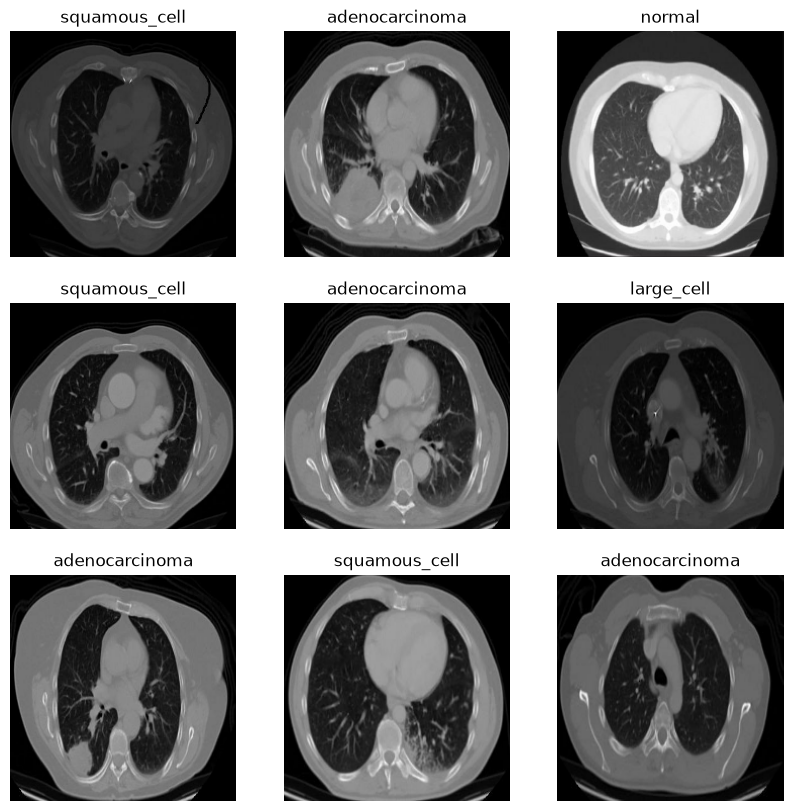

In [34]:
images, labels = next(iter(train_ds))
print(images.shape, labels.shape)      # (32, 224, 224, 3) (32, 4)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(train_ds.class_names[labels[i].numpy().argmax()])
    plt.axis("off")
plt.show()